# 02. Análise exploratória do dataset de contratos

Este notebook lê o dataset produzido por `01_dataset_exploratorio_novas_fontes.ipynb` e apresenta uma visão geral com gráficos clássicos e verificações simples.

Arquivos aceitos:

- `data/processed/dataset_exploratorio_contratos.parquet`
- `data/processed/dataset_exploratorio_contratos.csv`


In [21]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## 1. Localização do projeto e carregamento

In [22]:
def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "processed").exists():
            return candidate
    return current.parent if current.name == "notebooks" else current


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PARQUET_PATH = PROCESSED_DIR / "dataset_exploratorio_contratos.parquet"
CSV_PATH = PROCESSED_DIR / "dataset_exploratorio_contratos.csv"

if PARQUET_PATH.exists():
    df = pd.read_parquet(PARQUET_PATH)
    source_path = PARQUET_PATH
elif CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH, parse_dates=["data_corte"], low_memory=False)
    source_path = CSV_PATH
else:
    raise FileNotFoundError(
        "Dataset não encontrado. Execute primeiro o notebook "
        "01_dataset_exploratorio_novas_fontes.ipynb."
    )

for column in [
    "data_corte", "Data_assinatura_contrato", "Data_conclusao_contrato",
    "Data_conclusao", "Data_OS", "Data_Paralisacao", "Data_Prev_Retomada",
    "data_termino_vigente"
]:
    if column in df.columns:
        df[column] = pd.to_datetime(df[column], errors="coerce")

print("Arquivo:", source_path)
print("Linhas:", f"{len(df):,}")
print("Colunas:", df.shape[1])
print("Contratos:", df["id_contrato"].nunique())
print("Período:", df["data_corte"].min(), "a", df["data_corte"].max())


Arquivo: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\processed\dataset_exploratorio_contratos.parquet
Linhas: 7,942
Colunas: 49
Contratos: 374
Período: 0023-02-26 00:00:00 a 8202-08-11 00:00:00


## 2. Amostra e estrutura

In [23]:
display(df.head())
df.info()


,id_contrato,data_corte,data_evento_x,qtd_parcelas,qtd_parcelas_liberadas,valor_liberado,atraso_medio_parcela,atraso_maximo_parcela,qtd_parcelas_acumulado,qtd_parcelas_liberadas_acumulado,valor_liberado_acumulado,data_evento_y,qtd_aditivos_prazo,dias_aditados,data_termino_vigente,qtd_aditivos_prazo_acumulado,dias_aditados_acumulado,qtd_aditivos_valor,qtd_aditivos_valor_acumulado,Data_assinatura_contrato,Data_conclusao_contrato,numero_contrato,Tipo_de_contrato,Nome_predio,valor_total_contrato,tipo_obra,Descricao,prazo_total_informado,Observacao_contrato,id_fornecedor,Data_conclusao,Ano_contrato,Data_proposta,Data_Orcamento,Data_OS,status_contrato,Contrato_Paralisado,Data_Paralisacao,Motivo_Paralisacao,Data_Prev_Retomada,Contrato_concluido,Contrato_rescido,Predio_Numero_Classif,nome_fornecedor,percentual_financeiro_liberado,dias_ate_termino_vigente,dias_desde_os,flag_contrato_localizado,flag_percentual_financeiro_suspeito
0,9,2020-12-04,2020-12-04,1.00,1.00,"53,265.81",295.00,295.00,1.00,1.00,"53,265.81",NaT,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaT,NaT,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
1,10,2019-02-13,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-02-13,1.00,30.00,2019-02-13,1.00,30.00,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaT,NaT,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0,0
2,10,2019-06-03,2019-06-03,1.00,1.00,"4,052.21",189.00,189.00,1.00,1.00,"4,052.21",2019-02-13,1.00,30.00,2019-02-13,1.00,30.00,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaT,NaT,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,-110.00,NaN,0,0
3,10,2020-10-14,2020-10-14,1.00,1.00,"12,156.63",454.00,454.00,2.00,2.00,"16,208.84",2019-02-13,1.00,30.00,2019-02-13,1.00,30.00,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaT,NaT,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,-609.00,NaN,0,0
4,10,2021-05-17,2021-05-17,1.00,1.00,"6,078.31",103.00,103.00,3.00,3.00,"22,287.15",2019-02-13,1.00,30.00,2019-02-13,1.00,30.00,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaT,NaT,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,-824.00,NaN,0,0


<class 'pandas.DataFrame'>
RangeIndex: 7942 entries, 0 to 7941
Data columns (total 49 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   id_contrato                          7942 non-null   int64         
 1   data_corte                           7942 non-null   datetime64[us]
 2   data_evento_x                        7874 non-null   datetime64[us]
 3   qtd_parcelas                         7874 non-null   float64       
 4   qtd_parcelas_liberadas               7874 non-null   float64       
 5   valor_liberado                       7874 non-null   float64       
 6   atraso_medio_parcela                 7873 non-null   float64       
 7   atraso_maximo_parcela                7873 non-null   float64       
 8   qtd_parcelas_acumulado               7874 non-null   float64       
 9   qtd_parcelas_liberadas_acumulado     7874 non-null   float64       
 10  valor_liberado_acumulad

In [24]:
resumo_numerico = df.describe(include=[np.number]).T
resumo_numerico


,count,mean,std,min,25%,50%,75%,max
id_contrato,"7,942.00",200.46,98.88,9.00,118.00,195.00,268.00,427.00
qtd_parcelas,"7,874.00",1.54,1.32,1.00,1.00,1.00,2.00,28.00
qtd_parcelas_liberadas,"7,874.00",1.54,1.32,1.00,1.00,1.00,2.00,28.00
valor_liberado,"7,874.00","75,597.88","201,095.90","-1,140,240.12","1,225.50","7,474.80","54,147.10","3,217,828.84"
atraso_medio_parcela,"7,873.00",4.54,88.42,-862.00,0.00,0.00,0.00,"2,912.00"
atraso_maximo_parcela,"7,873.00",6.68,88.95,-862.00,0.00,0.00,0.00,"2,912.00"
qtd_parcelas_acumulado,"7,874.00",72.55,135.49,1.00,10.00,28.00,71.00,"1,063.00"
qtd_parcelas_liberadas_acumulado,"7,874.00",72.55,135.49,1.00,10.00,28.00,71.00,"1,063.00"
valor_liberado_acumulado,"7,874.00","1,715,080.14","3,365,803.52","-11,425.30","49,062.72","254,943.67","1,308,278.65","22,804,713.10"
qtd_aditivos_prazo,"2,400.00",1.00,0.06,1.00,1.00,1.00,1.00,2.00


## 3. Qualidade dos dados

In [25]:
qualidade = pd.DataFrame({
    "coluna": df.columns,
    "tipo": df.dtypes.astype(str).values,
    "nulos": df.isna().sum().values,
    "percentual_nulos": (df.isna().mean().values * 100).round(2),
    "valores_distintos": [df[column].nunique(dropna=True) for column in df.columns],
}).sort_values("percentual_nulos", ascending=False)

qualidade.head(25)


,coluna,tipo,nulos,percentual_nulos,valores_distintos
39,Data_Prev_Retomada,datetime64[us],7904,99.52,3
37,Data_Paralisacao,datetime64[us],7904,99.52,3
38,Motivo_Paralisacao,str,7904,99.52,3
32,Data_proposta,datetime64[us],7243,91.20,39
30,Data_conclusao,datetime64[us],7063,88.93,60
20,Data_conclusao_contrato,datetime64[us],7063,88.93,60
36,Contrato_Paralisado,str,6840,86.12,2
40,Contrato_concluido,str,6840,86.12,2
41,Contrato_rescido,str,6840,86.12,2
33,Data_Orcamento,datetime64[us],6825,85.94,49


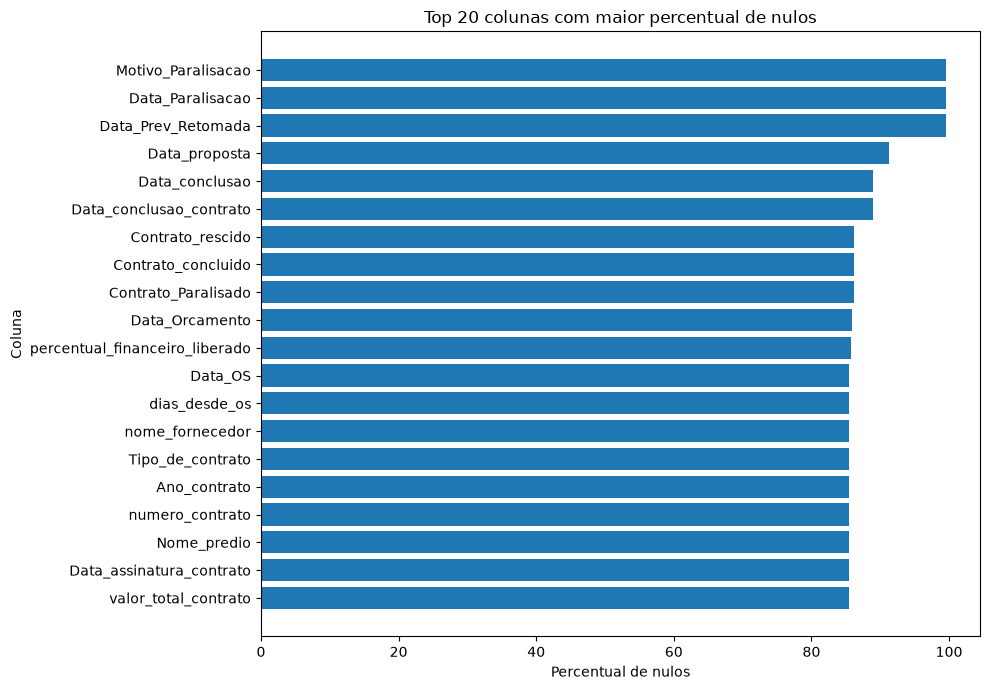

In [26]:
top_nulos = qualidade.head(20).sort_values("percentual_nulos")

plt.figure(figsize=(10, 7))
plt.barh(top_nulos["coluna"], top_nulos["percentual_nulos"])
plt.title("Top 20 colunas com maior percentual de nulos")
plt.xlabel("Percentual de nulos")
plt.ylabel("Coluna")
plt.tight_layout()
plt.show()


In [27]:
print("Duplicidades completas:", int(df.duplicated().sum()))
print(
    "Duplicidades por contrato e data de corte:",
    int(df.duplicated(["id_contrato", "data_corte"]).sum())
)


Duplicidades completas: 0
Duplicidades por contrato e data de corte: 0


## 4. Visão cadastral dos contratos

Para evitar contar o mesmo contrato várias vezes, esta seção usa apenas o snapshot mais recente de cada contrato.

In [28]:
latest = (
    df.sort_values(["id_contrato", "data_corte"])
    .groupby("id_contrato", as_index=False)
    .tail(1)
    .copy()
)

print("Contratos no recorte mais recente:", len(latest))
latest.head()


Contratos no recorte mais recente: 374


,id_contrato,data_corte,data_evento_x,qtd_parcelas,qtd_parcelas_liberadas,valor_liberado,atraso_medio_parcela,atraso_maximo_parcela,qtd_parcelas_acumulado,qtd_parcelas_liberadas_acumulado,valor_liberado_acumulado,data_evento_y,qtd_aditivos_prazo,dias_aditados,data_termino_vigente,qtd_aditivos_prazo_acumulado,dias_aditados_acumulado,qtd_aditivos_valor,qtd_aditivos_valor_acumulado,Data_assinatura_contrato,Data_conclusao_contrato,numero_contrato,Tipo_de_contrato,Nome_predio,valor_total_contrato,tipo_obra,Descricao,prazo_total_informado,Observacao_contrato,id_fornecedor,Data_conclusao,Ano_contrato,Data_proposta,Data_Orcamento,Data_OS,status_contrato,Contrato_Paralisado,Data_Paralisacao,Motivo_Paralisacao,Data_Prev_Retomada,Contrato_concluido,Contrato_rescido,Predio_Numero_Classif,nome_fornecedor,percentual_financeiro_liberado,dias_ate_termino_vigente,dias_desde_os,flag_contrato_localizado,flag_percentual_financeiro_suspeito
0,9,2020-12-04,2020-12-04,1.00,1.00,"53,265.81",295.00,295.00,1.00,1.00,"53,265.81",NaT,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaT,NaT,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
4,10,2021-05-17,2021-05-17,1.00,1.00,"6,078.31",103.00,103.00,3.00,3.00,"22,287.15",2019-02-13,1.00,30.00,2019-02-13,1.00,30.00,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaT,NaT,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,-824.00,NaN,0,0
12,11,2020-04-20,2020-04-20,2.00,2.00,"14,772.97",0.00,0.00,8.00,8.00,"390,675.38",NaT,NaN,NaN,NaT,NaN,NaN,1.00,2.00,2018-10-30,2020-01-15,160/2018,Obra,Concórdia,"276,770.81",Reforma Parcial,Reforma Parcial do Fórum de Concórdia - Substi...,150.00,Contrato em andamento,35.00,2020-01-15,"2,018.00",NaT,NaT,2019-07-24,CONCLUÍDO,Não,NaT,NaN,NaT,Sim,Não,Concórdia - 160/2018 - Reforma Parcial,AZ Construções Ltda.,1.41,NaN,271.00,1,0
13,14,2020-04-15,2020-04-15,1.00,1.00,"6,499.08",41.00,41.00,1.00,1.00,"6,499.08",NaT,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaT,NaT,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
20,15,2024-04-01,2024-04-01,1.00,1.00,"45,348.68",113.00,113.00,7.00,7.00,"252,380.92",NaT,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaT,NaT,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0


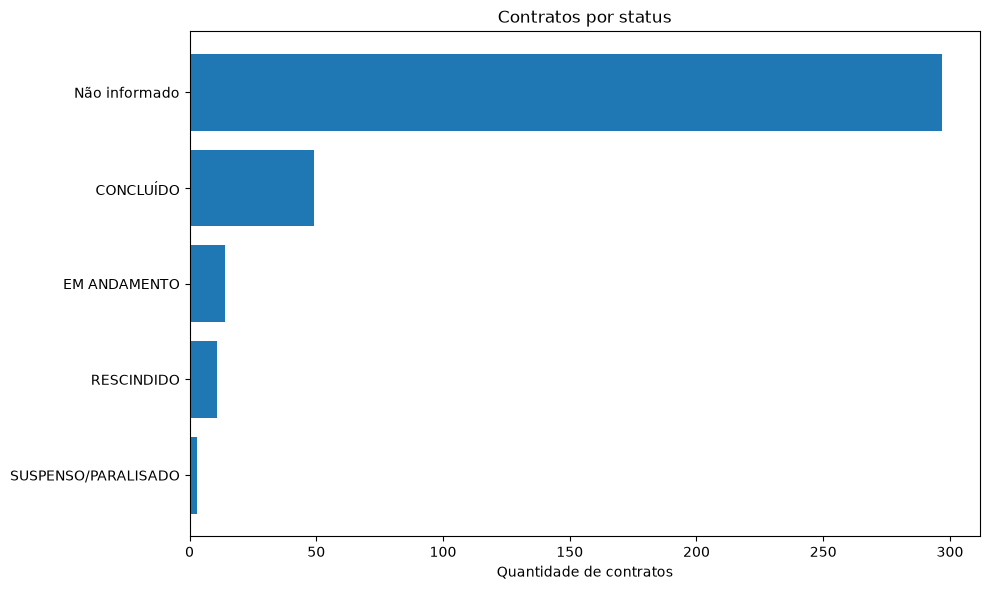

In [29]:
def plot_counts(series, title, top=15):
    counts = series.fillna("Não informado").value_counts().head(top).sort_values()
    plt.figure(figsize=(10, 6))
    plt.barh(counts.index.astype(str), counts.values)
    plt.title(title)
    plt.xlabel("Quantidade de contratos")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()


plot_counts(latest["status_contrato"], "Contratos por status")


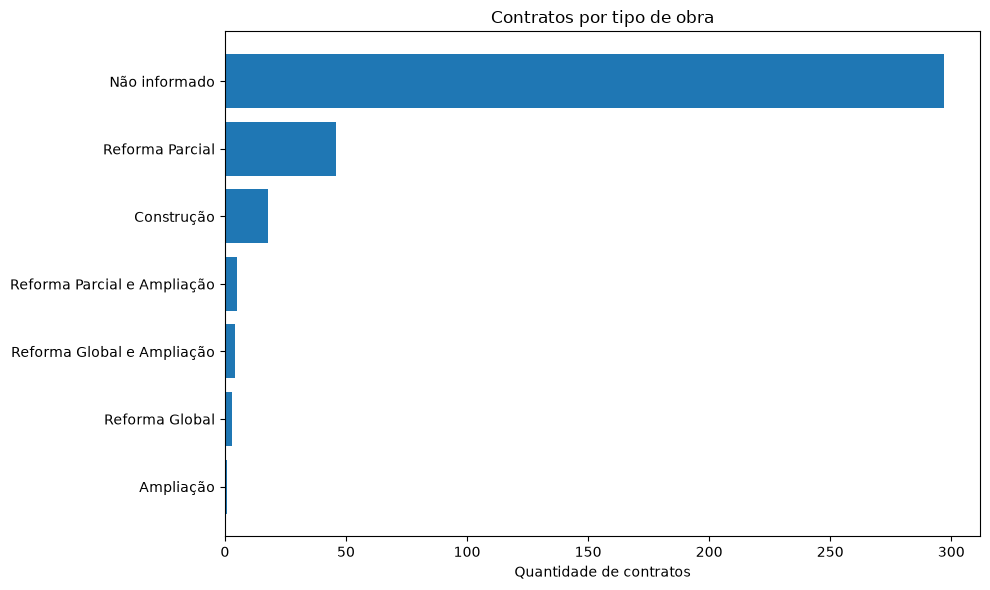

In [30]:
plot_counts(latest["tipo_obra"], "Contratos por tipo de obra")


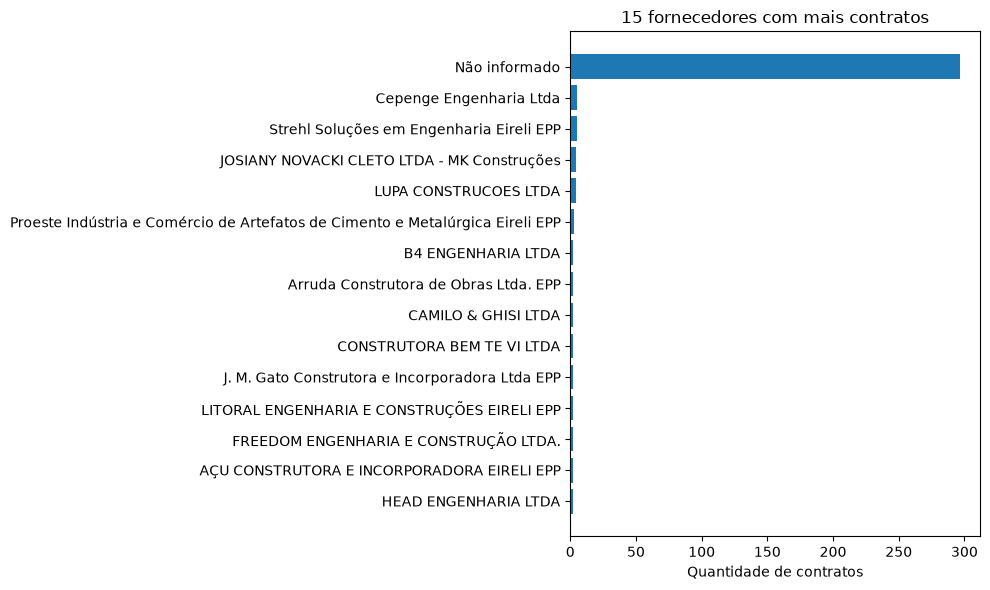

In [31]:
if "nome_fornecedor" in latest.columns:
    plot_counts(latest["nome_fornecedor"], "15 fornecedores com mais contratos", top=15)


## 5. Distribuição dos valores e prazos

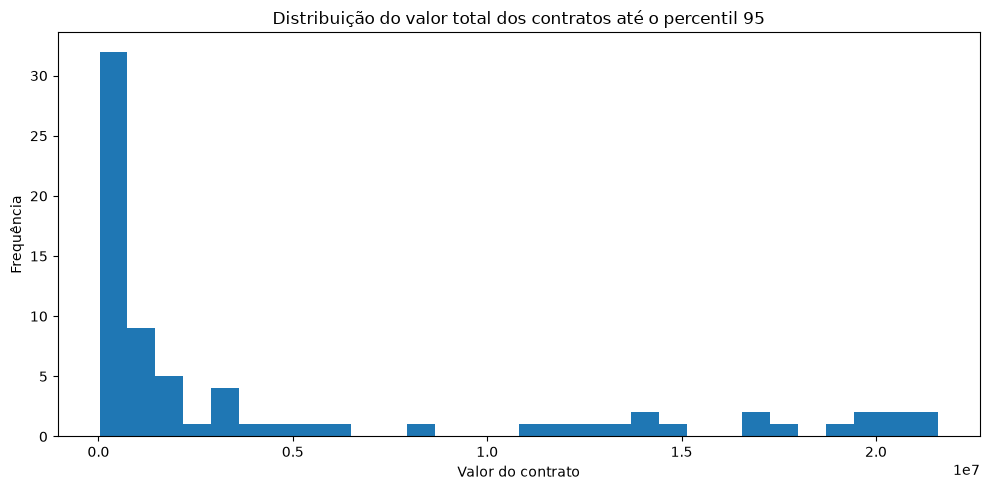

In [32]:
def histogram(series, title, xlabel, bins=30, upper_quantile=None):
    values = pd.to_numeric(series, errors="coerce").dropna()
    if upper_quantile is not None and not values.empty:
        values = values[values <= values.quantile(upper_quantile)]
    plt.figure(figsize=(10, 5))
    plt.hist(values, bins=bins)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Frequência")
    plt.tight_layout()
    plt.show()


histogram(
    latest["valor_total_contrato"],
    "Distribuição do valor total dos contratos até o percentil 95",
    "Valor do contrato",
    upper_quantile=0.95,
)


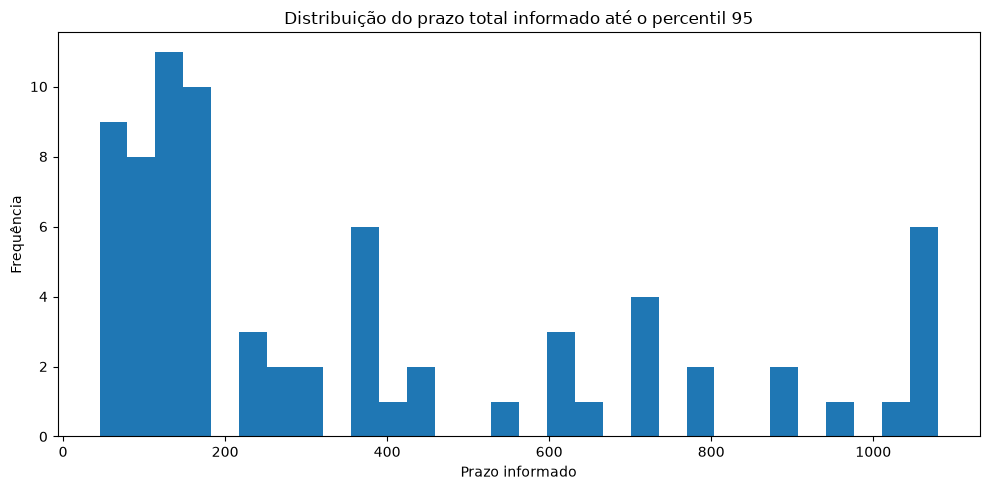

In [33]:
histogram(
    latest["prazo_total_informado"],
    "Distribuição do prazo total informado até o percentil 95",
    "Prazo informado",
    upper_quantile=0.95,
)


## 6. Parcelas e execução financeira

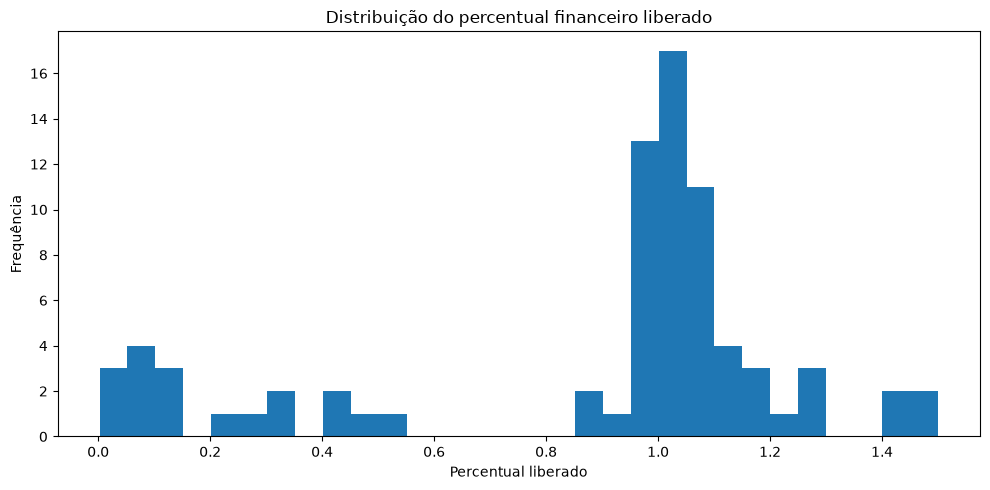

In [34]:
histogram(
    latest["percentual_financeiro_liberado"].clip(lower=0, upper=1.5),
    "Distribuição do percentual financeiro liberado",
    "Percentual liberado",
    bins=30,
)


In [35]:
financeiro = latest[[
    column for column in [
        "id_contrato", "valor_total_contrato", "valor_liberado_acumulado",
        "percentual_financeiro_liberado", "qtd_parcelas_acumulado",
        "qtd_parcelas_liberadas_acumulado"
    ] if column in latest.columns
]].copy()

financeiro.sort_values("percentual_financeiro_liberado", ascending=False).head(20)


,id_contrato,valor_total_contrato,valor_liberado_acumulado,percentual_financeiro_liberado,qtd_parcelas_acumulado,qtd_parcelas_liberadas_acumulado
298,49,"135,821.26","462,275.23",3.40,5.00,5.00
6551,288,"257,760.11","377,127.79",1.46,3.00,3.00
445,60,"3,213,805.64","4,547,358.79",1.41,33.00,33.00
12,11,"276,770.81","390,675.38",1.41,8.00,8.00
6993,317,"856,839.36","1,091,504.82",1.27,22.00,22.00
2985,153,"11,465,196.19","14,452,648.82",1.26,64.00,64.00
385,57,"1,100,000.00","1,375,788.64",1.25,43.00,43.00
415,59,"1,646,374.66","1,989,023.15",1.21,23.00,23.00
5386,254,"8,188,600.72","9,719,134.58",1.19,32.00,32.00
159,31,"376,739.26","437,195.07",1.16,8.00,8.00


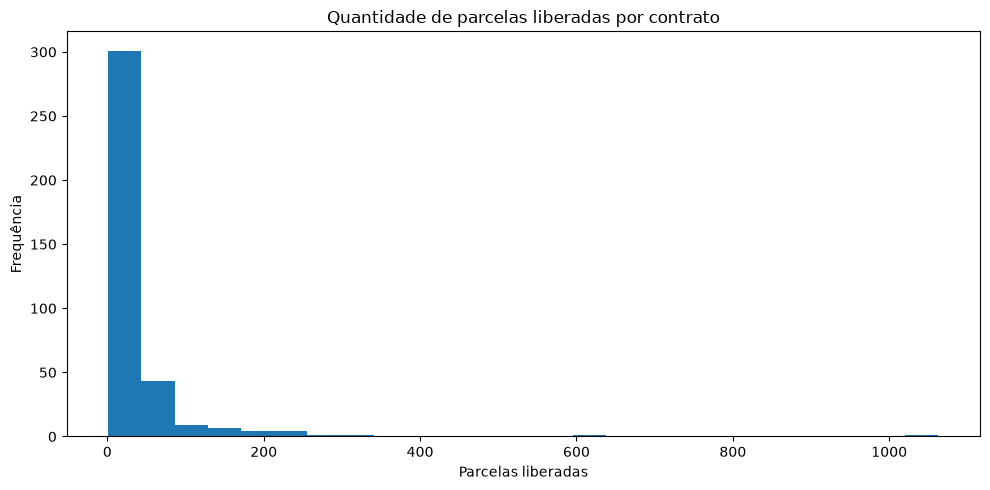

In [36]:
if "qtd_parcelas_liberadas_acumulado" in latest.columns:
    histogram(
        latest["qtd_parcelas_liberadas_acumulado"],
        "Quantidade de parcelas liberadas por contrato",
        "Parcelas liberadas",
        bins=25,
    )


## 7. Aditivos de prazo e valor

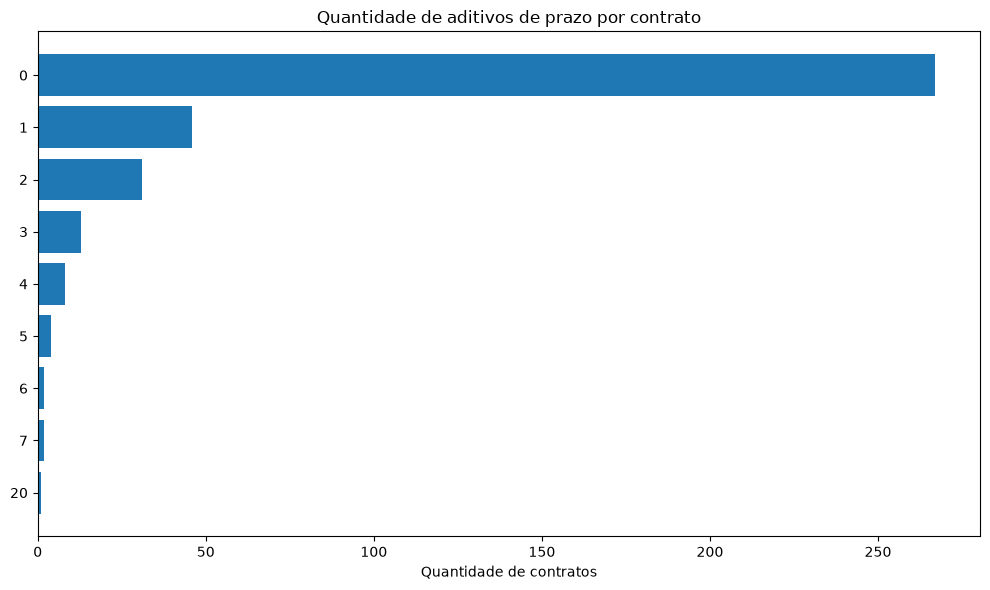

In [37]:
if "qtd_aditivos_prazo_acumulado" in latest.columns:
    plot_counts(
        latest["qtd_aditivos_prazo_acumulado"].fillna(0).astype(int),
        "Quantidade de aditivos de prazo por contrato",
        top=15,
    )


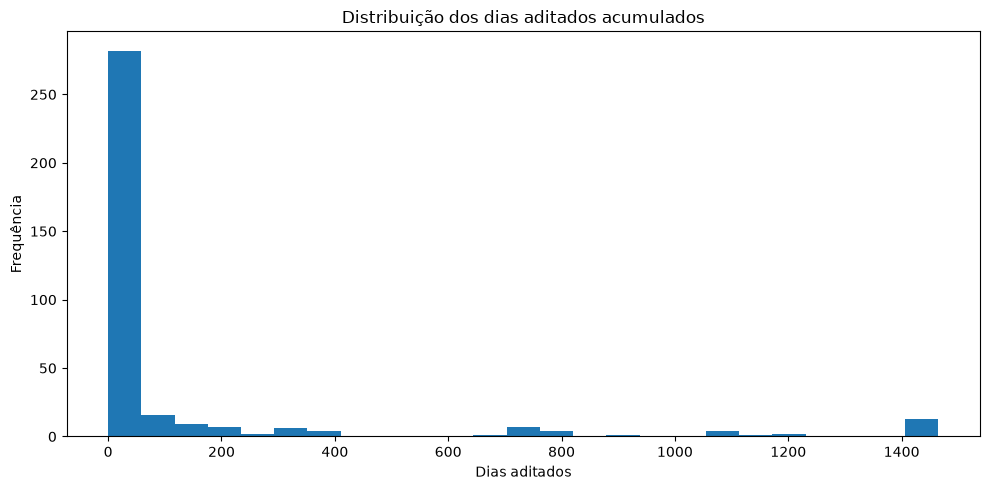

In [38]:
if "dias_aditados_acumulado" in latest.columns:
    histogram(
        latest["dias_aditados_acumulado"].fillna(0),
        "Distribuição dos dias aditados acumulados",
        "Dias aditados",
        bins=25,
        upper_quantile=0.95,
    )


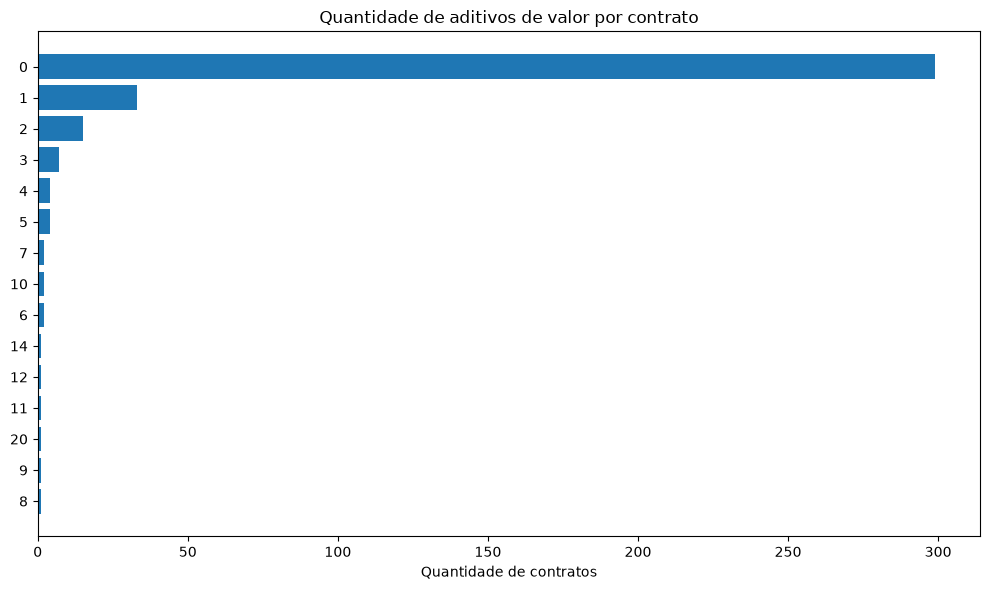

In [39]:
if "qtd_aditivos_valor_acumulado" in latest.columns:
    plot_counts(
        latest["qtd_aditivos_valor_acumulado"].fillna(0).astype(int),
        "Quantidade de aditivos de valor por contrato",
        top=15,
    )


## 8. Evolução temporal

In [40]:
data_minima = pd.Timestamp("2014-01-01")  # ajuste ao histórico esperado
data_maxima = pd.Timestamp.today().normalize()

datas_validas = df["data_corte"].between(data_minima, data_maxima)
df_temporal = df.loc[datas_validas].copy()

print("Registros fora do intervalo:", int((~datas_validas).sum()))
display(df.loc[~datas_validas, ["id_contrato", "data_corte"]])

Registros fora do intervalo: 9


,id_contrato,data_corte
1600,100,8202-08-11
1709,105,23-02-26
3265,167,202-04-07
3357,167,2502-05-20
4201,212,24-12-06
5340,246,2027-07-25
6612,292,204-05-24
7011,327,25-12-02
7643,402,2026-11-16


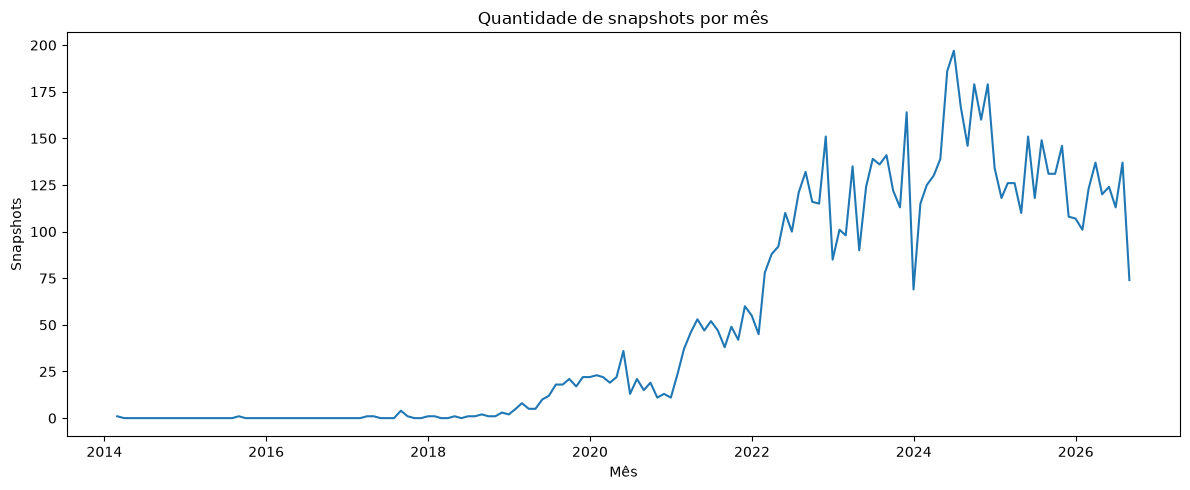

In [41]:
snapshots_month = (
    df_temporal.set_index("data_corte")
    .resample("ME")
    .size()
)

plt.figure(figsize=(12, 5))
plt.plot(snapshots_month.index, snapshots_month.values)
plt.title("Quantidade de snapshots por mês")
plt.xlabel("Mês")
plt.ylabel("Snapshots")
plt.tight_layout()
plt.show()


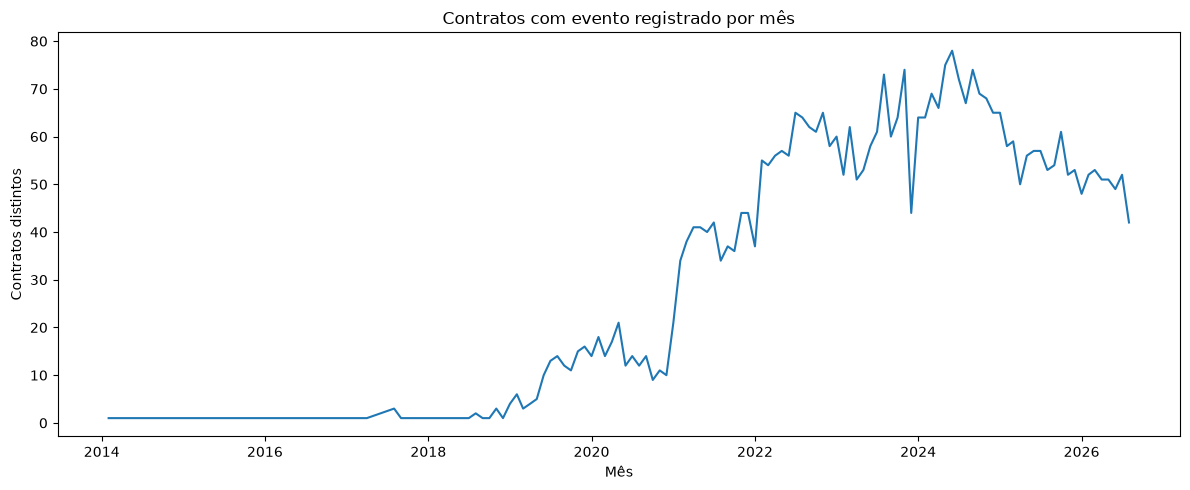

In [42]:
contracts_month = (
    df_temporal.assign(
        mes=lambda data: data["data_corte"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby("mes")["id_contrato"]
    .nunique()
)

plt.figure(figsize=(12, 5))
plt.plot(contracts_month.index, contracts_month.values)
plt.title("Contratos com evento registrado por mês")
plt.xlabel("Mês")
plt.ylabel("Contratos distintos")
plt.tight_layout()
plt.show()


## 9. Relações entre variáveis numéricas

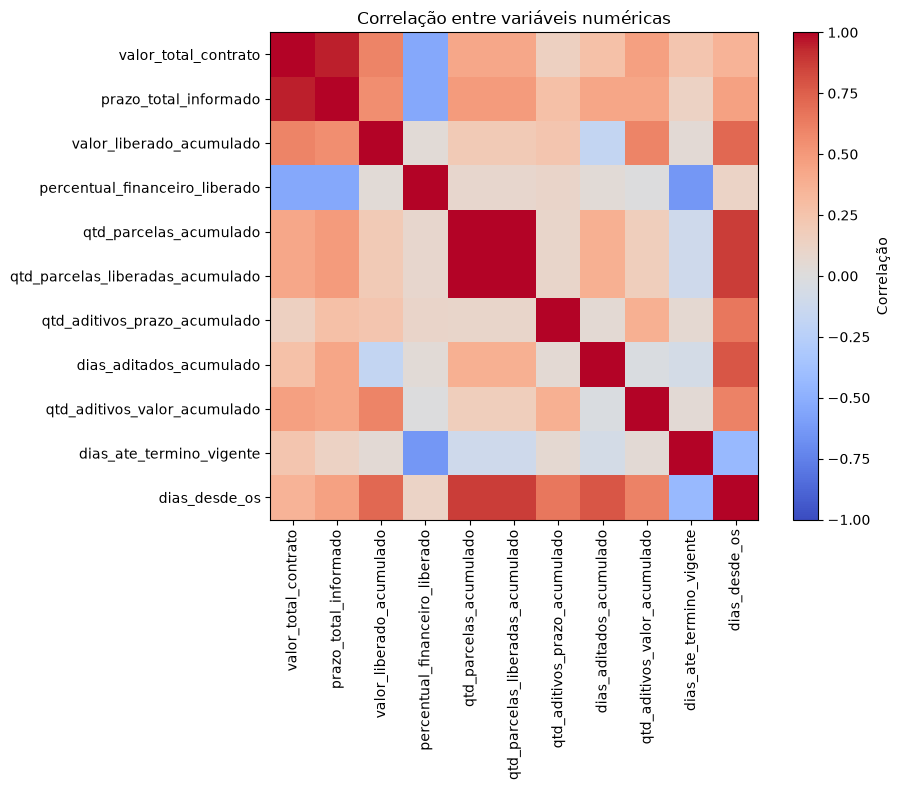

In [43]:
candidate_numeric = [
    "valor_total_contrato", "prazo_total_informado", "valor_liberado_acumulado",
    "percentual_financeiro_liberado", "qtd_parcelas_acumulado",
    "qtd_parcelas_liberadas_acumulado", "qtd_aditivos_prazo_acumulado",
    "dias_aditados_acumulado", "qtd_aditivos_valor_acumulado",
    "dias_ate_termino_vigente", "dias_desde_os"
]
numeric_columns = [column for column in candidate_numeric if column in latest.columns]
correlation = latest[numeric_columns].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation.columns)))
ax.set_xticklabels(correlation.columns, rotation=90)
ax.set_yticks(range(len(correlation.index)))
ax.set_yticklabels(correlation.index)
fig.colorbar(image, ax=ax, label="Correlação")
ax.set_title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()


## 10. Registros suspeitos

In [44]:
suspeitos = latest[
    latest.get("flag_percentual_financeiro_suspeito", pd.Series(0, index=latest.index)).eq(1)
].copy()

print("Contratos com percentual financeiro suspeito:", len(suspeitos))
suspeitos[[
    column for column in [
        "id_contrato", "numero_contrato", "valor_total_contrato",
        "valor_liberado_acumulado", "percentual_financeiro_liberado"
    ] if column in suspeitos.columns
]].head(20)


Contratos com percentual financeiro suspeito: 1


,id_contrato,numero_contrato,valor_total_contrato,valor_liberado_acumulado,percentual_financeiro_liberado
298,49,110/2019,"135,821.26","462,275.23",3.40


In [45]:
datas_futuras = df[df["data_corte"] > pd.Timestamp.today().normalize()].copy()
print("Snapshots com data de corte futura:", len(datas_futuras))
datas_futuras[["id_contrato", "data_corte"]].head(20)


Snapshots com data de corte futura: 4


,id_contrato,data_corte
1600,100,8202-08-11
3357,167,2502-05-20
5340,246,2027-07-25
7643,402,2026-11-16


## 11. Resumo final

In [46]:
resumo_final = pd.DataFrame({
    "Indicador": [
        "Snapshots",
        "Contratos distintos",
        "Data de corte mínima",
        "Data de corte máxima",
        "Contratos concluídos",
        "Contratos com aditivo de prazo",
        "Contratos com aditivo de valor",
        "Contratos com percentual financeiro suspeito",
    ],
    "Valor": [
        len(df),
        df["id_contrato"].nunique(),
        df["data_corte"].min(),
        df["data_corte"].max(),
        int(latest["status_contrato"].astype("string").str.upper().eq("CONCLUÍDO").sum()),
        int(latest.get("qtd_aditivos_prazo_acumulado", pd.Series(0, index=latest.index)).fillna(0).gt(0).sum()),
        int(latest.get("qtd_aditivos_valor_acumulado", pd.Series(0, index=latest.index)).fillna(0).gt(0).sum()),
        len(suspeitos),
    ],
})
resumo_final


,Indicador,Valor
0,Snapshots,7942
1,Contratos distintos,374
2,Data de corte mínima,0023-02-26 00:00:00
3,Data de corte máxima,8202-08-11 00:00:00
4,Contratos concluídos,49
5,Contratos com aditivo de prazo,107
6,Contratos com aditivo de valor,75
7,Contratos com percentual financeiro suspeito,1


## Leitura recomendada

- Use `df` para analisar todos os snapshots.
- Use `latest` para comparar contratos sem contar o mesmo contrato várias vezes.
- Colunas com muitos nulos devem ser avaliadas antes da modelagem.
- Percentuais financeiros acima de 1,5 permanecem sinalizados, sem exclusão automática.
